Von MP4 zu Audio + Background
Original MP4
   ↓ Extract audio (keep original SR)
   ↓ Separate vocals/background (at original SR)
   ↓ Convert vocals & background stems → 48 kHz WAV
   ↓ Denoise vocals (48 kHz WAV) for Synthesis
   ↓ Transcripe text using the original Audio
Audio + Background   



In [1]:
import os
import shutil
import shlex
import subprocess
import demucs.separate
from df.enhance import enhance, init_df, load_audio, save_audio
import whisper
import json



def load_whisper_model(model_size="base"):
    """Load the Whisper model."""
    print(f"Loading Whisper {model_size} model...")
    model = whisper.load_model(model_size)
    print(f"Whisper {model_size} model loaded successfully.")
    return model

def separate_vocals(input_audio_path, output_dir, model='mdx_extra'):
    """
    Separate vocals and no-vocals with Demucs and save to custom output_dir.
    """
    print(f"Separating vocals from {input_audio_path}...")

    # Run Demucs CLI separation
    cmd = f'--two-stems vocals -n {model} "{input_audio_path}"'
    demucs.separate.main(shlex.split(cmd))

    base_name = os.path.splitext(os.path.basename(input_audio_path))[0]
    demucs_output_dir = os.path.join("separated", model, base_name)

    vocals_src = os.path.join(demucs_output_dir, "vocals.wav")
    no_vocals_src = os.path.join(demucs_output_dir, "no_vocals.wav")

    os.makedirs(output_dir, exist_ok=True)

    vocals_dst = os.path.join(output_dir, f"{base_name}_vocals.wav")
    no_vocals_dst = os.path.join(output_dir, f"{base_name}_no_vocals.wav")

    shutil.copy2(vocals_src, vocals_dst)
    shutil.copy2(no_vocals_src, no_vocals_dst)

    print(f"Vocals saved to: {vocals_dst}")
    print(f"No vocals saved to: {no_vocals_dst}")

    return vocals_dst, no_vocals_dst  # Return paths of saved files


def convert_to_48k_wav(input_audio_path, output_wav_path):
    """
    Convert any audio input to 48kHz stereo WAV using ffmpeg.
    """
    print(f"Converting {input_audio_path} to 48kHz WAV at {output_wav_path}...")
    subprocess.run([
        'ffmpeg', '-y', '-i', input_audio_path,
        '-ar', '48000',
        '-ac', '2',
        output_wav_path
    ], check=True)
    print("Conversion done.")


def denoise_audio(input_wav_path, output_wav_path):
    """
    Denoise/enhance the WAV audio using DeepFilterNet.
    """
    print(f"Denoising audio {input_wav_path} to {output_wav_path}...")
    model, df_state, _ = init_df()
    audio, _ = load_audio(input_wav_path, sr=df_state.sr())
    enhanced = enhance(model, df_state, audio)
    save_audio(output_wav_path, enhanced, df_state.sr())
    print("Denoising done.")



def separate_audio_from_video(video_path, audio_out_path, muted_video_out_path):
    """Extract audio from video and save both audio and muted video separately."""
    
    # Ensure output directories exist
    os.makedirs(os.path.dirname(audio_out_path), exist_ok=True)
    os.makedirs(os.path.dirname(muted_video_out_path), exist_ok=True)
    
    # Extract audio (48 kHz mono WAV)
    audio_cmd = [
        "ffmpeg", "-y", "-i", video_path,
        "-vn", "-acodec", "pcm_s16le", "-ar", "48000", "-ac", "1",
        audio_out_path
    ]

    # Remove audio from video
    muted_video_cmd = [
        "ffmpeg", "-y", "-i", video_path,
        "-an", muted_video_out_path
    ]

    print("🔊 Extracting audio...")
    subprocess.run(audio_cmd, check=True)
    print(f"✅ Audio saved to: {audio_out_path}")

    print("🎥 Saving muted video...")
    subprocess.run(muted_video_cmd, check=True)
    print(f"✅ Muted video saved to: {muted_video_out_path}")

def transcribe_audio(model, audio_file_path, language=None):
    """Transcribe audio using Whisper and return full result including timestamps."""
    print(f"Transcribing audio file: {audio_file_path}")
    
    options = {
        "verbose": True,
        "task": "transcribe"
    }
    if language:
        options["language"] = language
    
    result = model.transcribe(audio_file_path, **options)
    print(f"Transcription complete. Found {len(result.get('segments', []))} segments.")
    return result


def write_transcription_to_json(result, output_path):
    """Write the full Whisper transcription result to a JSON file."""
    os.makedirs(os.path.dirname(output_path), exist_ok=True)  # Create output dir
    with open(output_path, "w", encoding="utf-8") as f:
        json.dump(result, f, indent=2, ensure_ascii=False)
    print(f"✅ JSON transcript saved to: {output_path}")



/venv/lib/python3.10/site-packages/df/io.py:9: UserWarning: `torchaudio.backend.common.AudioMetaData` has been moved to `torchaudio.AudioMetaData`. Please update the import path.
  from torchaudio.backend.common import AudioMetaData


I use a function to make sure all audio, video, etc. are in one folder. To increase structure of the repo

In [2]:
def generate_pipeline_paths(video_path, base_output="../output"):
    video_title = os.path.splitext(os.path.basename(video_path))[0]
    root_dir = os.path.join(base_output, video_title)

    return {
        "root": root_dir,
        "audio_raw": os.path.join(root_dir, "audio", "original_unprocessed.wav"),
        "audio_vocals": os.path.join(root_dir, "audio", "vocals_raw.wav"),
        "audio_vocals_48k": os.path.join(root_dir, "audio", "vocals_48k.wav"),
        "audio_vocals_denoised": os.path.join(root_dir, "audio", "vocals_denoised.wav"),
        "video_muted": os.path.join(root_dir, "video", "video_muted.mp4"),
        "video_final": os.path.join(root_dir, "video", "video_final.mp4"),
        "transcript_json": os.path.join(root_dir, "transcripts", "transcript.json"),
        "demucs_out": os.path.join(root_dir, "demucs")
    }


this is the main function to use the entire pipeline 

Von MP4 zu Audio + Background + Transcriped text
   

In [3]:
def full_video_audio_pipeline(video_path, model_size="base", base_output="../output"):
    from df.enhance import enhance, init_df, load_audio, save_audio
    import whisper

    paths = generate_pipeline_paths(video_path, base_output)
    os.makedirs(paths["root"], exist_ok=True)

    # Step 1: Separate audio and muted video
    separate_audio_from_video(video_path, paths["audio_raw"], paths["video_muted"])

    # Step 2: Separate vocals with Demucs
    vocals_path, _ = separate_vocals(paths["audio_raw"], output_dir=os.path.dirname(paths["audio_vocals"]))
    shutil.move(vocals_path, paths["audio_vocals"])  # Rename into our structure

    # Step 3: Convert vocals to 48kHz WAV
    convert_to_48k_wav(paths["audio_vocals"], paths["audio_vocals_48k"])

    # Step 4: Denoise vocals
    model_df, df_state, _ = init_df()
    audio, _ = load_audio(paths["audio_vocals_48k"], sr=df_state.sr())
    enhanced = enhance(model_df, df_state, audio)
    save_audio(paths["audio_vocals_denoised"], enhanced, df_state.sr())

    # Step 5: Transcribe with Whisper
    whisper_model = whisper.load_model(model_size)
    # result = transcribe_audio(whisper_model, paths["audio_vocals_denoised"]) #["audio_vocals_denoised"] eigdl aber des is scheisse deswegen
    result = transcribe_audio(whisper_model, paths["audio_raw"])
    write_transcription_to_json(result, paths["transcript_json"])

    print(f"🎉 Pipeline complete. All outputs saved under: {paths['root']}")
    return paths


Here is how to use this pipeline:

In [4]:
video_path = "../input/green_nature.mp4"
pipeline_paths = full_video_audio_pipeline(video_path, model_size="base")


🔊 Extracting audio...


ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enab

✅ Audio saved to: ../output/green_nature/audio/original_unprocessed.wav
🎥 Saving muted video...


ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enab

✅ Muted video saved to: ../output/green_nature/video/video_muted.mp4
Separating vocals from ../output/green_nature/audio/original_unprocessed.wav...


...

Vocals saved to: ../output/green_nature/audio/original_unprocessed_vocals.wav
No vocals saved to: ../output/green_nature/audio/original_unprocessed_no_vocals.wav
Converting ../output/green_nature/audio/vocals_raw.wav to 48kHz WAV at ../output/green_nature/audio/vocals_48k.wav...


ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enab

Conversion done.
2025-06-20 13:50:38 | INFO     | DF | Running on torch 2.3.0+cu121
2025-06-20 13:50:38 | INFO     | DF | Running on host c05024c7636c
2025-06-20 13:50:38 | INFO     | DF | Loading model settings of DeepFilterNet3
2025-06-20 13:50:38 | INFO     | DF | Using DeepFilterNet3 model at /root/.cache/DeepFilterNet/DeepFilterNet3
2025-06-20 13:50:38 | INFO     | DF | Initializing model `deepfilternet3`
2025-06-20 13:50:38 | INFO     | DF | Found checkpoint /root/.cache/DeepFilterNet/DeepFilterNet3/checkpoints/model_120.ckpt.best with epoch 120
2025-06-20 13:50:38 | INFO     | DF | Running on device cuda:0
2025-06-20 13:50:38 | INFO     | DF | Model loaded


fatal: not a git repository (or any of the parent directories): .git
/venv/lib/python3.10/site-packages/torch/nn/modules/conv.py:456: UserWarning: Plan failed with a cudnnException: CUDNN_BACKEND_EXECUTION_PLAN_DESCRIPTOR: cudnnFinalize Descriptor Failed cudnn_status: CUDNN_STATUS_NOT_SUPPORTED (Triggered internally at ../aten/src/ATen/native/cudnn/Conv_v8.cpp:919.)
  return F.conv2d(input, weight, bias, self.stride,
100%|███████████████████████████████████████| 139M/139M [00:11<00:00, 13.0MiB/s]


Transcribing audio file: ../output/green_nature/audio/original_unprocessed.wav
Detecting language using up to the first 30 seconds. Use `--language` to specify the language
Detected language: English
[00:00.000 --> 00:07.000]  And here, when conditions are just right, it's possible to witness a rare and remarkable spectacle.
[00:08.000 --> 00:13.000]  The river is so crystal clear that its bait is bathed in sunlight.
[00:14.000 --> 00:19.000]  A magical landscape, a miniature mountains and valleys.
[00:22.000 --> 00:29.000]  As the sun times in the sky, bubbles of gas appear.
[00:31.000 --> 00:34.000]  Evidence of photosynthesis.
[00:35.000 --> 00:42.000]  They absorb carbon dioxide and use the sun's power to synthesize the sugars that the plant needs to grow.
[00:48.000 --> 00:55.000]  Now in late afternoon, bubbles of oxygen make the river water fizz like champagne.
[00:56.000 --> 01:04.000]  The plants can become so violent with gas that they rise to the surface, even carrying the b

In [5]:
import difflib
import os

def compare_transcriptions(whisper_model, paths, language=None, max_chars=500):
    """
    Compare transcriptions from raw, vocals, and denoised audio using Whisper.
    
    Args:
        whisper_model: Loaded Whisper model
        paths: Dictionary from generate_pipeline_paths() with all file paths
        language: Optional language code for transcription
        max_chars: Number of characters to preview in each transcript
    """
    
    print("🔍 Comparing transcriptions from different audio versions...")

    # Transcribe all versions
    result_raw = transcribe_audio(whisper_model, paths["audio_raw"], language)
    result_vocals = transcribe_audio(whisper_model, paths["audio_vocals"], language)
    result_denoised = transcribe_audio(whisper_model, paths["audio_vocals_denoised"], language)

    # Extract text
    text_raw = result_raw["text"].strip()
    text_vocals = result_vocals["text"].strip()
    text_denoised = result_denoised["text"].strip()

    # Print first few lines of each
    print("\n--- RAW AUDIO ---\n", text_raw[:max_chars])
    print("\n--- VOCALS ONLY ---\n", text_vocals[:max_chars])
    print("\n--- DENOISED VOCALS ---\n", text_denoised[:max_chars])

    # Compare similarities
    sim_raw_vs_vocals = difflib.SequenceMatcher(None, text_raw, text_vocals).ratio()
    sim_raw_vs_denoised = difflib.SequenceMatcher(None, text_raw, text_denoised).ratio()
    sim_vocals_vs_denoised = difflib.SequenceMatcher(None, text_vocals, text_denoised).ratio()

    print("\n🔗 Similarity Scores:")
    print(f"Raw vs Vocals:     {sim_raw_vs_vocals:.2%}")
    print(f"Raw vs Denoised:   {sim_raw_vs_denoised:.2%}")
    print(f"Vocals vs Denoised:{sim_vocals_vs_denoised:.2%}")

    # Save all transcripts
    out_dir = os.path.join(paths["root"], "transcripts")
    os.makedirs(out_dir, exist_ok=True)
    write_transcription_to_json(result_raw, os.path.join(out_dir, "raw.json"))
    write_transcription_to_json(result_vocals, os.path.join(out_dir, "vocals.json"))
    write_transcription_to_json(result_denoised, os.path.join(out_dir, "denoised.json"))

    print("\n📝 All transcripts saved for manual review.")


In [6]:
model = load_whisper_model("base")
video_path = "../input/green_nature.mp4"
paths = generate_pipeline_paths(video_path)

compare_transcriptions(model, paths)


Loading Whisper base model...
Whisper base model loaded successfully.
🔍 Comparing transcriptions from different audio versions...
Transcribing audio file: ../output/green_nature/audio/original_unprocessed.wav
Detecting language using up to the first 30 seconds. Use `--language` to specify the language
Detected language: English
[00:00.000 --> 00:07.000]  And here, when conditions are just right, it's possible to witness a rare and remarkable spectacle.
[00:08.000 --> 00:13.000]  The river is so crystal clear that its bait is bathed in sunlight.
[00:14.000 --> 00:19.000]  A magical landscape, a miniature mountains and valleys.
[00:22.000 --> 00:29.000]  As the sun times in the sky, bubbles of gas appear.
[00:31.000 --> 00:34.000]  Evidence of photosynthesis.
[00:35.000 --> 00:42.000]  They absorb carbon dioxide and use the sun's power to synthesize the sugars that the plant needs to grow.
[00:48.000 --> 00:55.000]  Now in late afternoon, bubbles of oxygen make the river water fizz like 

In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt

def plot_waveform(audio_path, title="Waveform"):
    y, sr = librosa.load(audio_path, sr=None)
    plt.figure(figsize=(14, 3))
    librosa.display.waveshow(y, sr=sr)
    plt.title(title)
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


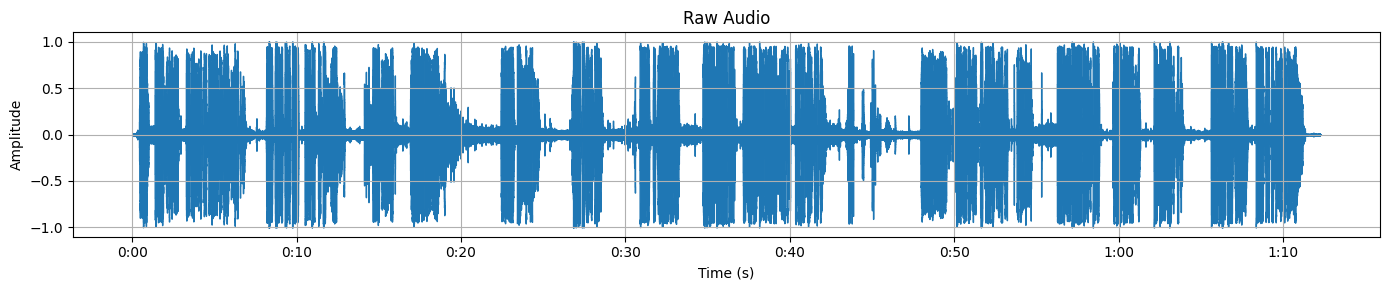

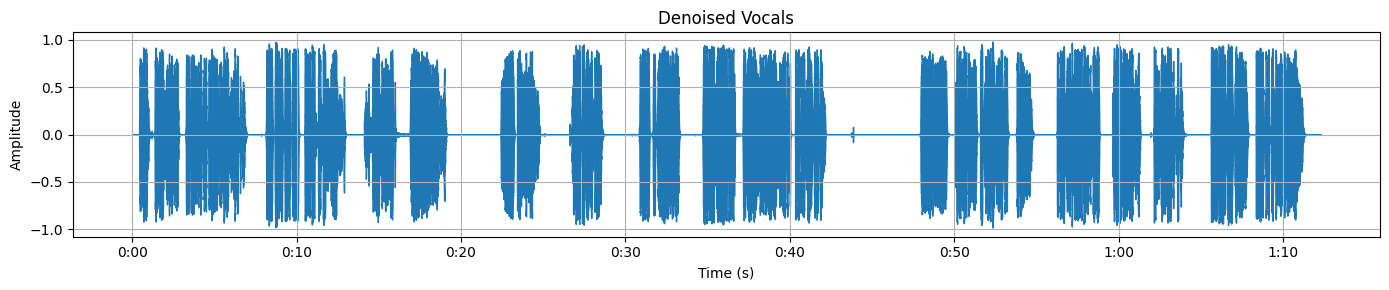

In [2]:
plot_waveform("../output/green_nature/audio/original_unprocessed.wav", title="Raw Audio")
plot_waveform("../output/green_nature/audio/vocals_denoised.wav", title="Denoised Vocals")


In [7]:
import numpy as np
def plot_spectrogram(audio_path, title="Spectrogram"):
    y, sr = librosa.load(audio_path, sr=None)
    D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)

    plt.figure(figsize=(14, 4))
    librosa.display.specshow(D, sr=sr, x_axis='time', y_axis='log')
    plt.title(title)
    plt.colorbar(format='%+2.0f dB')
    plt.tight_layout()
    plt.show()


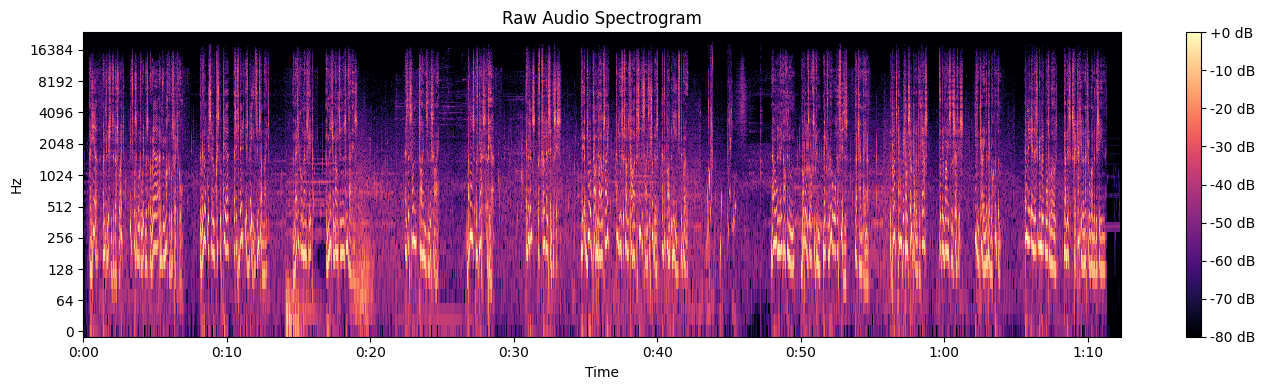

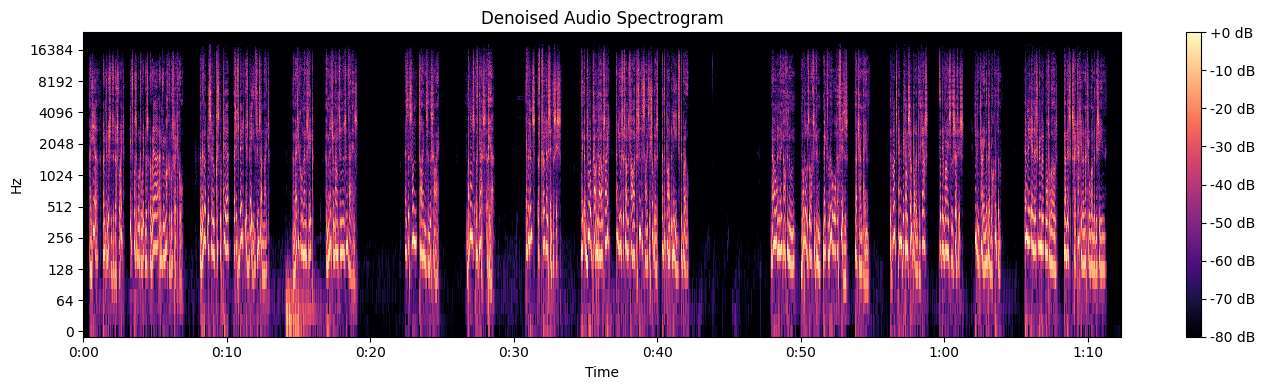

In [8]:
plot_spectrogram("../output/green_nature/audio/original_unprocessed.wav", title="Raw Audio Spectrogram")
plot_spectrogram("../output/green_nature/audio/vocals_denoised.wav", title="Denoised Audio Spectrogram")
